# Flight Delay Prediction


**Project objective:** Compare Logistic Regression, Random Forest, XGBoost, and LightGBM for predicting whether a flight arrives at least 15 minutes late, then use SHAP to explain the selected model.

**Dataset:** U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data supplied as `dataset(1).csv`.

**Primary target:** `ARR_DEL15` — 1 means arrival delay of 15 minutes or more; 0 means the flight did not arrive 15 or more minutes late.





## 1. Environment setup



In [ ]:
# Install packages needed for XGBoost, LightGBM, and SHAP.
%pip -q install xgboost lightgbm shap

## 2. Import libraries and configure reproducibility

This cell imports data processing, visualisation, modelling, evaluation, and explainability tools. A fixed random seed makes random operations more reproducible.

In [ ]:
import os
import sys
import warnings
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

import xgboost as xgb
import lightgbm as lgb
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("XGBoost:", xgb.__version__)
print("LightGBM:", lgb.__version__)
print("SHAP:", shap.__version__)

Python: 3.13.16
pandas: 2.2.3
scikit-learn: 1.6.1
XGBoost: 3.4.1
LightGBM: 4.6.0
SHAP: 0.52.0


## 3. Upload and load the dataset



In [ ]:
from google.colab import files

uploaded = files.upload()

# Select the first uploaded CSV automatically.
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("No CSV file was uploaded. Please upload dataset(1).csv.")
DATA_PATH = csv_files[0]

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()

print(f"Loaded file: {DATA_PATH}")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Saving dataset.csv to dataset.csv
Loaded file: dataset.csv
Dataset shape: 539,747 rows × 21 columns


,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,AIR_TIME,DISTANCE
0,2025,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,500,452.0,-8.0,16.0,10.0,754,733.0,-21.0,0.0,0.0,0.0,75.0,569.0
1,2025,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,555,552.0,-3.0,13.0,13.0,849,832.0,-17.0,0.0,0.0,0.0,74.0,569.0
2,2025,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,820,815.0,-5.0,13.0,11.0,1114,1052.0,-22.0,0.0,0.0,0.0,73.0,569.0
3,2025,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,1032,1029.0,-3.0,12.0,5.0,1323,1300.0,-23.0,0.0,0.0,0.0,74.0,569.0
4,2025,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,1700,1707.0,7.0,20.0,19.0,1948,2005.0,17.0,1.0,0.0,0.0,79.0,569.0


## 4. Initial data inspection

The following checks show column names, data types, missing values, duplicate rows, and basic descriptive statistics. These checks help identify issues before modelling.

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values by column (largest first):")
missing_summary = (
    df.isna().sum()
      .to_frame("missing_count")
      .assign(missing_percent=lambda x: (x["missing_count"] / len(df) * 100).round(2))
      .sort_values("missing_count", ascending=False)
)
display(missing_summary[missing_summary["missing_count"] > 0])

print(f"\nExact duplicate rows: {df.duplicated().sum():,}")
display(df.describe(include="all").T)

Column names:
['YEAR', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'FL_DATE', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'ARR_DEL15', 'CANCELLED', 'DIVERTED', 'AIR_TIME', 'DISTANCE']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   YEAR               539747 non-null  int64  
 1   MONTH              539747 non-null  int64  
 2   DAY_OF_MONTH       539747 non-null  int64  
 3   DAY_OF_WEEK        539747 non-null  int64  
 4   FL_DATE            539747 non-null  object 
 5   OP_UNIQUE_CARRIER  539747 non-null  object 
 6   ORIGIN             539747 non-null  object 
 7   DEST               539747 non-null  object 
 8   CRS_DEP_TIME       539747 non-null  int64  
 9   DEP_TIME           523861 non-nu

,missing_count,missing_percent
ARR_DELAY,17478,3.24
AIR_TIME,17478,3.24
ARR_DEL15,17478,3.24
TAXI_IN,16580,3.07
ARR_TIME,16580,3.07
TAXI_OUT,16227,3.01
DEP_DELAY,15923,2.95
DEP_TIME,15886,2.94



Exact duplicate rows: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
YEAR,539747.0,NaN,NaN,NaN,2025.0,0.0,2025.0,2025.0,2025.0,2025.0,2025.0
MONTH,539747.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
DAY_OF_MONTH,539747.0,NaN,NaN,NaN,15.831995,9.036782,1.0,8.0,16.0,24.0,31.0
DAY_OF_WEEK,539747.0,NaN,NaN,NaN,4.019748,1.925782,1.0,2.0,4.0,6.0,7.0
FL_DATE,539747,31,1/5/2025 12:00:00 AM,19676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OP_UNIQUE_CARRIER,539747,14,WN,105307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ORIGIN,539747,329,DFW,25124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEST,539747,329,DFW,25125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CRS_DEP_TIME,539747.0,NaN,NaN,NaN,1315.739317,480.555061,5.0,905.0,1310.0,1725.0,2359.0
DEP_TIME,523861.0,NaN,NaN,NaN,1320.868158,491.902766,1.0,911.0,1319.0,1731.0,2400.0


## 5. Validate expected columns and clean basic issues

The project proposal identifies `ARR_DEL15` as the classification outcome. The notebook checks that it exists and converts common numeric fields safely. Exact duplicate rows are removed, while missing target rows are excluded from supervised training because their class is unknown.

Cancelled and diverted flights need careful handling: arrival-delay labels may be undefined for these records. The primary modelling sample therefore excludes cancelled/diverted flights when those columns are available.

In [ ]:
# Confirm that the target exists before proceeding.
TARGET = "ARR_DEL15"
if TARGET not in df.columns:
    raise KeyError(f"Required target column '{TARGET}' was not found. Check the uploaded CSV.")

# Remove exact duplicate records to avoid counting the same row twice.
before = len(df)
df = df.drop_duplicates().copy()
print(f"Removed {before - len(df):,} exact duplicate rows.")

# Convert expected numeric columns to numeric values where present.
numeric_candidates = [
    "YEAR", "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "CRS_DEP_TIME",
    "CRS_ARR_TIME", "DEP_TIME", "ARR_TIME", "DEP_DELAY", "ARR_DELAY",
    "CANCELLED", "DIVERTED", "DISTANCE", "TAXI_OUT", "TAXI_IN",
    "AIR_TIME", "ARR_DEL15"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Exclude cancelled and diverted records from the primary arrival-delay task.
rows_before_status_filter = len(df)
for status_col in ["CANCELLED", "DIVERTED"]:
    if status_col in df.columns:
        # Treat a missing status flag as unknown, not automatically as a positive status.
        df = df[df[status_col].fillna(0).eq(0)].copy()

print(f"Rows excluded as cancelled/diverted: {rows_before_status_filter - len(df):,}")

# Remove rows without a known target and ensure the target is binary.
rows_before_target = len(df)
df = df[df[TARGET].notna()].copy()
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)
print(f"Rows removed for missing/invalid target: {rows_before_target - len(df):,}")
print("Clean modelling dataset shape:", df.shape)

print("\nTarget counts:")
display(df[TARGET].value_counts(dropna=False).rename(index={0: "Not delayed by 15+ minutes", 1: "Delayed by 15+ minutes"}).to_frame("count"))
print("\nTarget proportions:")
display(df[TARGET].value_counts(normalize=True).sort_index().rename(index={0: "0 = Not delayed", 1: "1 = Delayed"}).mul(100).round(2).to_frame("percent"))

Removed 1 exact duplicate rows.
Rows excluded as cancelled/diverted: 17,477
Rows removed for missing/invalid target: 0
Clean modelling dataset shape: (522269, 21)

Target counts:


,count
ARR_DEL15,
Not delayed by 15+ minutes,424139
Delayed by 15+ minutes,98130



Target proportions:


,percent
ARR_DEL15,
0 = Not delayed,81.21
1 = Delayed,18.79


## 6. Exploratory Data Analysis (EDA)

EDA explores the target balance, delays by airline, scheduled departure hour, and the distribution of arrival delays. Plots are intended to reveal patterns and guide interpretation, not to prove causation.

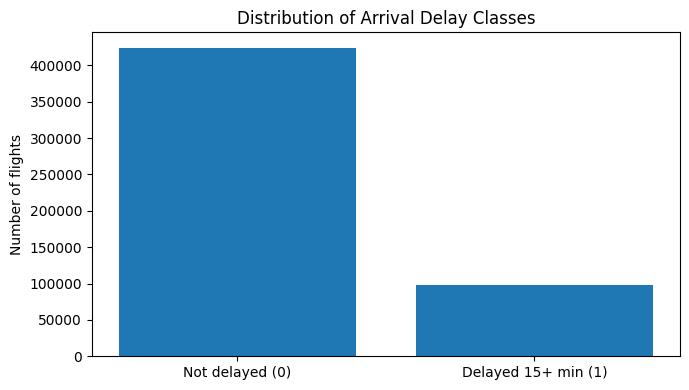

/tmp/ipykernel_546/2913801101.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], errors="coerce")


,delay_rate,flight_count
OP_UNIQUE_CARRIER,,
F9,26.0%,15110
OH,25.5%,19151
B6,24.5%,17558
G4,23.7%,9206
OO,20.9%,63502
DL,19.3%,74025
AA,19.2%,72082
MQ,18.4%,20831
NK,18.1%,16946


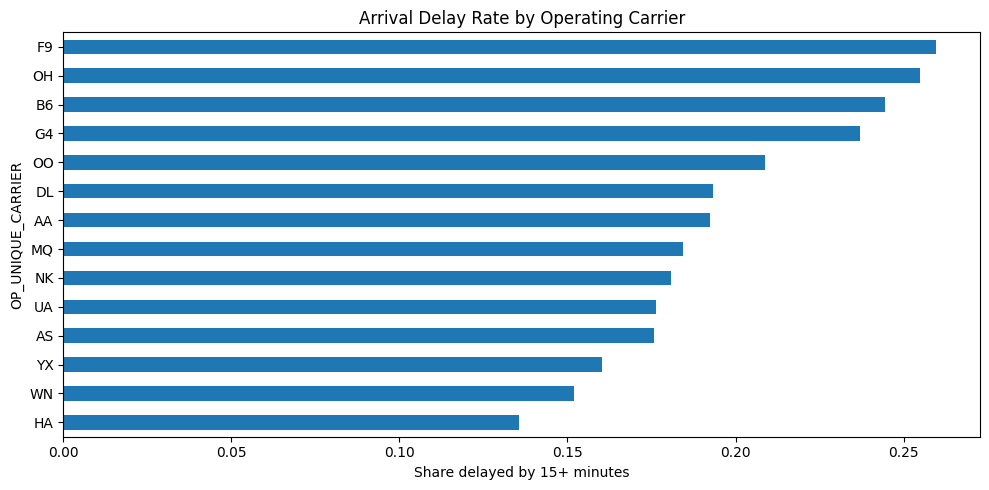

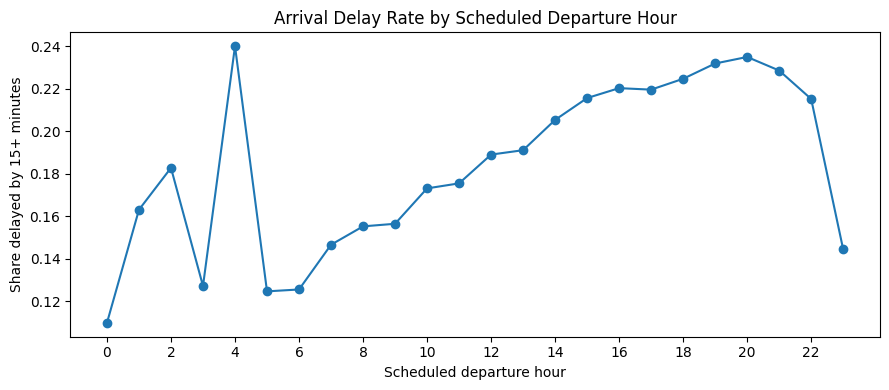

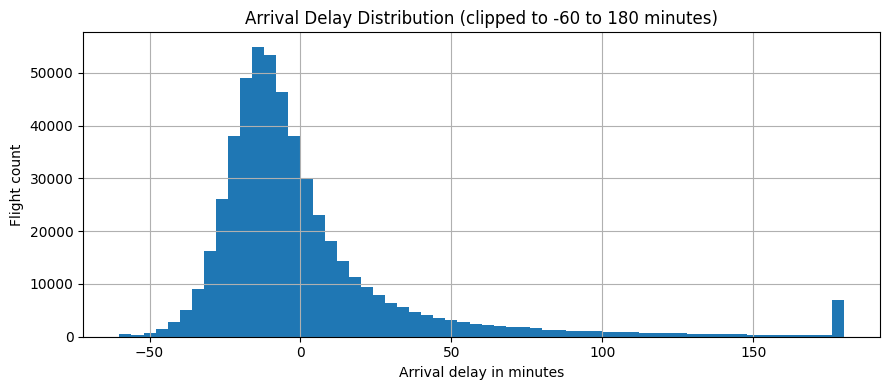

In [ ]:
# 6.1 Target class distribution
target_counts = df[TARGET].value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(["Not delayed (0)", "Delayed 15+ min (1)"], [target_counts.get(0, 0), target_counts.get(1, 0)])
plt.title("Distribution of Arrival Delay Classes")
plt.ylabel("Number of flights")
plt.tight_layout()
plt.show()

# 6.2 Parse flight date if available.
if "FL_DATE" in df.columns:
    df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], errors="coerce")
elif {"YEAR", "MONTH", "DAY_OF_MONTH"}.issubset(df.columns):
    df["FL_DATE"] = pd.to_datetime(
        dict(year=df["YEAR"], month=df["MONTH"], day=df["DAY_OF_MONTH"]),
        errors="coerce"
    )

# 6.3 Delay rate by airline
if "OP_UNIQUE_CARRIER" in df.columns:
    airline_delay = df.groupby("OP_UNIQUE_CARRIER")[TARGET].agg(["mean", "count"]).sort_values("mean", ascending=False)
    airline_delay = airline_delay.rename(columns={"mean": "delay_rate", "count": "flight_count"})
    display(airline_delay.head(15).style.format({"delay_rate": "{:.1%}"}))
    plt.figure(figsize=(10, 5))
    airline_delay["delay_rate"].sort_values().plot(kind="barh")
    plt.title("Arrival Delay Rate by Operating Carrier")
    plt.xlabel("Share delayed by 15+ minutes")
    plt.tight_layout()
    plt.show()

# 6.4 Scheduled departure hour
def hhmm_to_hour(series):
    # Converts HHMM-like values (e.g., 5 -> 00:05, 730 -> 07:30, 1530 -> 15:30) to hour.
    values = pd.to_numeric(series, errors="coerce")
    values = values.where((values >= 0) & (values <= 2359))
    hour = np.floor(values / 100)
    minute = values % 100
    valid = (hour <= 23) & (minute <= 59)
    return hour.where(valid)

if "CRS_DEP_TIME" in df.columns:
    df["SCHED_DEP_HOUR"] = hhmm_to_hour(df["CRS_DEP_TIME"])
    hourly_delay = df.groupby("SCHED_DEP_HOUR")[TARGET].mean().dropna()
    plt.figure(figsize=(9, 4))
    hourly_delay.plot(marker="o")
    plt.title("Arrival Delay Rate by Scheduled Departure Hour")
    plt.xlabel("Scheduled departure hour")
    plt.ylabel("Share delayed by 15+ minutes")
    plt.xticks(range(0, 24, 2))
    plt.tight_layout()
    plt.show()

# 6.5 Arrival delay distribution, where available
if "ARR_DELAY" in df.columns:
    plt.figure(figsize=(9, 4))
    df["ARR_DELAY"].dropna().clip(-60, 180).hist(bins=60)
    plt.title("Arrival Delay Distribution (clipped to -60 to 180 minutes)")
    plt.xlabel("Arrival delay in minutes")
    plt.ylabel("Flight count")
    plt.tight_layout()
    plt.show()

## 7. Define the prediction task and prevent target leakage

**Task definition:** Predict `ARR_DEL15` using information intended to be available before scheduled departure.

To keep this a meaningful pre-departure prediction, the primary feature set excludes actual departure/arrival times, departure/arrival delays, taxi times, air time, and other direct outcome information. `ARR_DELAY` and `ARR_DEL15` must never be input features. The notebook uses scheduled timings, date/calendar information, carrier, route, and distance when available.

This is a deliberate modelling decision: a different prediction time (for example, after take-off) would justify a different feature set and should be described as a different task.

In [ ]:
# Candidate features known or scheduled before departure.
candidate_features = [
    "YEAR", "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK",
    "CRS_DEP_TIME", "CRS_ARR_TIME",
    "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DISTANCE"
]
FEATURES = [col for col in candidate_features if col in df.columns]

if not FEATURES:
    raise ValueError("None of the expected pre-departure features were found in the dataset.")

# Add a derived scheduled departure hour if the scheduled departure time exists.
if "SCHED_DEP_HOUR" in df.columns and "CRS_DEP_TIME" in FEATURES:
    FEATURES = [c for c in FEATURES if c != "CRS_DEP_TIME"] + ["SCHED_DEP_HOUR"]

# Explicitly check that known leakage columns are not included.
for forbidden in ["ARR_DEL15", "ARR_DELAY", "DEP_DELAY", "DEP_TIME", "ARR_TIME", "TAXI_OUT", "TAXI_IN", "AIR_TIME"]:
    if forbidden in FEATURES:
        raise ValueError(f"Potential leakage feature detected: {forbidden}")

print("Target:", TARGET)
print("Selected features:", FEATURES)
print("\nFeature data types:")
display(df[FEATURES].dtypes.to_frame("dtype"))

Target: ARR_DEL15
Selected features: ['YEAR', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'CRS_ARR_TIME', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'DISTANCE', 'SCHED_DEP_HOUR']

Feature data types:


,dtype
YEAR,int64
MONTH,int64
DAY_OF_MONTH,int64
DAY_OF_WEEK,int64
CRS_ARR_TIME,int64
OP_UNIQUE_CARRIER,object
ORIGIN,object
DEST,object
DISTANCE,float64
SCHED_DEP_HOUR,float64


## 8. Prepare the data and create a chronological holdout

A chronological split is preferred for this time-dependent problem: earlier flights are used for training and later flights are held out for testing. If dates are available, the final 20% of observations by date are reserved for testing. The test set is not used for model selection.

**Limitation:** Because this supplied file contains only January 2025, the test set is a later portion of the same month, not a genuinely independent future month or year.

In [18]:

# ============================================================
# 8. PREPARE DATA AND CREATE A CHRONOLOGICAL HOLDOUT
# ============================================================

# Ensure the flight date is in datetime format.
model_df = df.copy()

model_df["FL_DATE"] = pd.to_datetime(
    model_df["FL_DATE"], errors="coerce"
)

# Keep records with valid dates and known binary targets.
model_df = model_df.dropna(subset=["FL_DATE", TARGET]).copy()
model_df = model_df[model_df[TARGET].isin([0, 1])].copy()
model_df[TARGET] = model_df[TARGET].astype(int)

# Sort chronologically.
model_df = model_df.sort_values("FL_DATE").reset_index(drop=True)

# Split at a unique-date boundary, not a row boundary.
unique_dates = np.sort(
    model_df["FL_DATE"].dt.normalize().unique()
)

if len(unique_dates) < 2:
    raise ValueError("At least two distinct flight dates are required.")

cutoff_index = int(len(unique_dates) * 0.80)
cutoff_index = min(max(cutoff_index, 1), len(unique_dates) - 1)
cutoff_date = pd.Timestamp(unique_dates[cutoff_index])

train_df = model_df[
    model_df["FL_DATE"].dt.normalize() < cutoff_date
].copy()

test_df = model_df[
    model_df["FL_DATE"].dt.normalize() >= cutoff_date
].copy()

# Separate features and target.
X_train = train_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()
y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()

# Verify that dates do not overlap.
train_dates = set(train_df["FL_DATE"].dt.normalize().unique())
test_dates = set(test_df["FL_DATE"].dt.normalize().unique())

assert train_dates.isdisjoint(test_dates)
assert len(X_train) > 0 and len(X_test) > 0

if y_train.nunique() != 2 or y_test.nunique() != 2:
    raise ValueError(
        "Both partitions must contain delayed and non-delayed flights."
    )

split_method = "Chronological split by unique flight date (80/20)"

print("Split method:", split_method)
print("Training records:", f"{len(train_df):,}")
print("Test records:", f"{len(test_df):,}")
print("Training period:",
      train_df["FL_DATE"].min().date(), "to",
      train_df["FL_DATE"].max().date())
print("Testing period:",
      test_df["FL_DATE"].min().date(), "to",
      test_df["FL_DATE"].max().date())
print("Overlapping dates:", len(train_dates.intersection(test_dates)))
print(f"Training delay rate: {y_train.mean():.2%}")
print(f"Test delay rate: {y_test.mean():.2%}")


Split method: Chronological split by unique flight date (80/20)
Training records: 403,782
Test records: 118,487
Training period: 2025-01-01 to 2025-01-24
Testing period: 2025-01-25 to 2025-01-31
Overlapping dates: 0
Training delay rate: 20.89%
Test delay rate: 11.62%


## 9. Preprocessing pipeline

Numeric fields are median-imputed and standardised for Logistic Regression. Categorical fields are imputed with the most frequent category and one-hot encoded. The same fitted preprocessing pipeline is applied to the test data, avoiding information leakage from test-set statistics.

One-hot encoding can create many columns for airports and carriers. The implementation uses `handle_unknown='ignore'` so a category present only in the test set will not crash prediction.

In [19]:

# ============================================================
# 9. PREPROCESSING PIPELINE
# ============================================================

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_features = [
    c for c in FEATURES
    if pd.api.types.is_numeric_dtype(X_train[c])
]
categorical_features = [
    c for c in FEATURES if c not in numeric_features
]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['YEAR', 'MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'CRS_ARR_TIME', 'DISTANCE', 'SCHED_DEP_HOUR']
Categorical features: ['OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST']


## 10. Train the four proposed classification models

This section implements the four algorithms named in the project proposal. A single shared preprocessing pipeline ensures consistent input preparation. Class imbalance is addressed for Logistic Regression and Random Forest using balanced class weights; the boosted models use their respective positive-class weighting options.

The initial settings are deliberately moderate so the notebook is practical to run. They can be tuned after baseline results are available.

In [20]:

# ============================================================
# 10. TRAIN FOUR CLASSIFICATION MODELS
# ============================================================

import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import xgboost as xgb
import lightgbm as lgb

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=800,
        class_weight="balanced",
        solver="saga",
        tol=1e-3,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=2,
        max_features="sqrt",
        max_samples=0.8,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "XGBoost": xgb.XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.08,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=max(
            1.0,
            (y_train == 0).sum() / max(1, (y_train == 1).sum())
        ),
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "LightGBM": lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.08,
        num_leaves=31,
        class_weight="balanced",
        verbosity=-1,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

print("Preprocessing data...")
start = time.time()

fitted_preprocessor = clone(preprocessor)
X_train_processed = fitted_preprocessor.fit_transform(
    X_train, y_train
)
X_test_processed = fitted_preprocessor.transform(X_test)

print("Training matrix:", X_train_processed.shape)
print("Test matrix:", X_test_processed.shape)
print(f"Preprocessing time: {(time.time()-start)/60:.2f} minutes")

fitted_models = {}
evaluation_rows = []
prediction_store = {}

for name, estimator in models.items():
    print(f"\nTraining {name}...")
    start = time.time()

    estimator.fit(X_train_processed, y_train)

    y_pred = estimator.predict(X_test_processed)
    y_prob = estimator.predict_proba(X_test_processed)[:, 1]

    fitted_models[name] = Pipeline([
        ("preprocessor", fitted_preprocessor),
        ("model", estimator)
    ])

    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training_Time_Minutes": (time.time()-start)/60
    })

    prediction_store[name] = {
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    print(
        f"Completed in {evaluation_rows[-1]['Training_Time_Minutes']:.2f} min"
    )

results_df = (
    pd.DataFrame(evaluation_rows)
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)

display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "Training_Time_Minutes": "{:.2f}"
}))

best_model_name = results_df.iloc[0]["Model"]
best_pipeline = fitted_models[best_model_name]

print("Best model by F1-score:", best_model_name)


Preprocessing data...
Training matrix: (403782, 679)
Test matrix: (118487, 679)
Preprocessing time: 0.03 minutes

Training Logistic Regression...
Completed in 0.53 min

Training Random Forest...
Completed in 18.70 min

Training XGBoost...
Completed in 0.12 min

Training LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Completed in 0.15 min


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training_Time_Minutes
0,Logistic Regression,0.7610,0.1561,0.2398,0.1891,0.5646,0.53
1,Random Forest,0.7428,0.1474,0.2536,0.1865,0.5571,18.70
2,XGBoost,0.7646,0.1365,0.1925,0.1598,0.5428,0.12
3,LightGBM,0.7486,0.1259,0.1958,0.1533,0.5240,0.15


Best model by F1-score: Logistic Regression


## 11. Compare model performance visually

The table and chart provide a consistent comparison across all four models. F1-score is used as the default ranking metric because the task has imbalanced classes and both missed delays and false delay alerts matter. The other metrics remain important and should be reported alongside F1-score; the final choice should reflect the operational goal.

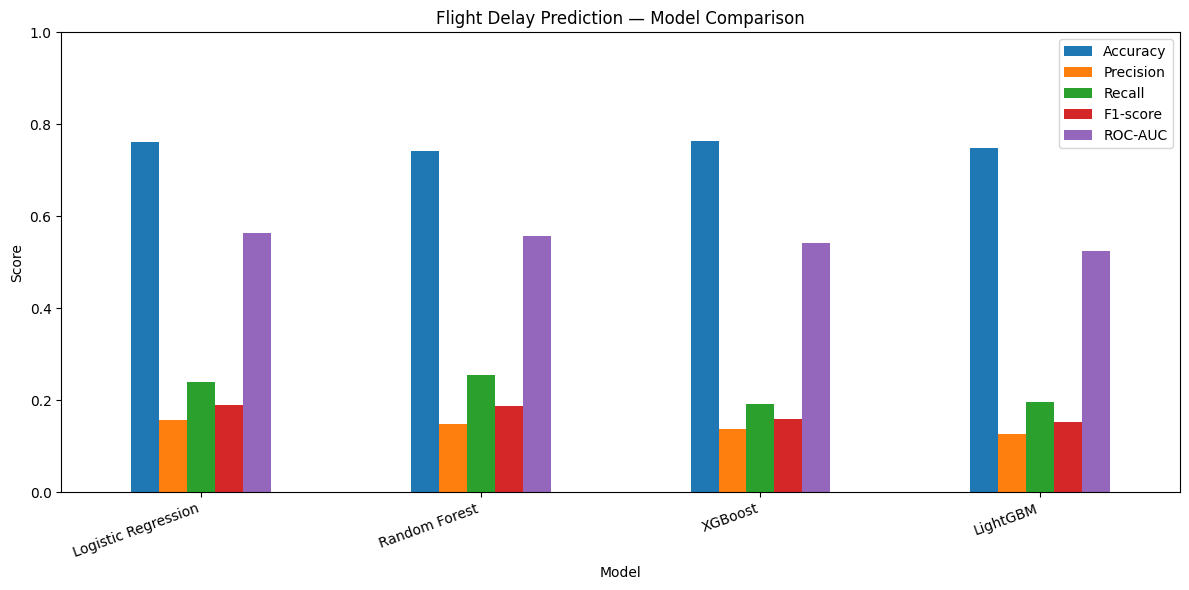

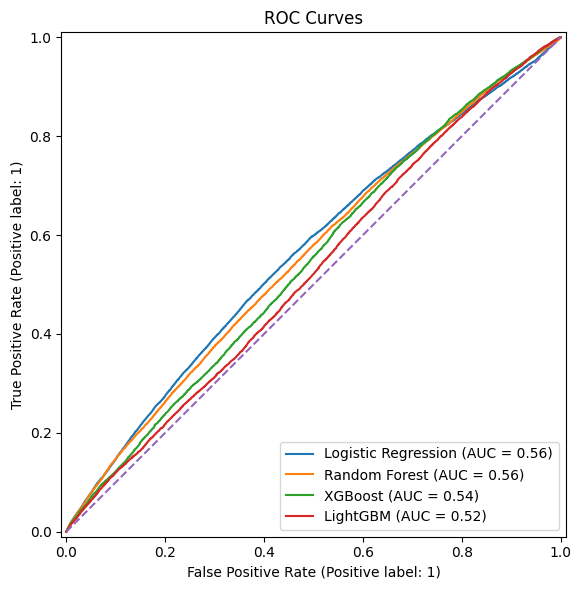

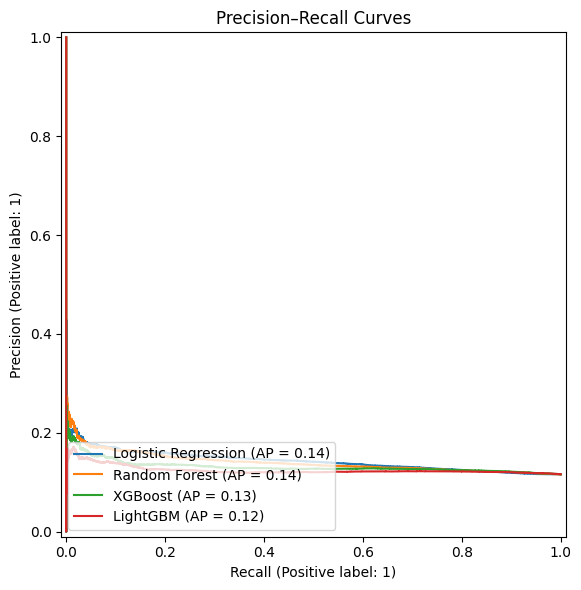

In [21]:

# ============================================================
# 11. MODEL COMPARISON VISUALISATIONS
# ============================================================

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

metric_columns = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1)
)
plt.title("Flight Delay Prediction — Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, pred in prediction_store.items():
    RocCurveDisplay.from_predictions(
        y_test, pred["y_prob"], name=name, ax=ax
    )
ax.plot([0, 1], [0, 1], "--")
ax.set_title("ROC Curves")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, pred in prediction_store.items():
    PrecisionRecallDisplay.from_predictions(
        y_test, pred["y_prob"], name=name, ax=ax
    )
ax.set_title("Precision–Recall Curves")
plt.tight_layout()
plt.show()


## 12. Inspect the selected model in detail

The model with the highest test F1-score is selected as the initial winner. This is a data-driven selection, not a pre-decided outcome. Inspect the confusion matrix and classification report to understand which class errors are occurring.

Selected model: Logistic Regression
                     precision    recall  f1-score   support

        Not delayed       0.89      0.83      0.86    104719
Delayed 15+ minutes       0.16      0.24      0.19     13768

           accuracy                           0.76    118487
          macro avg       0.52      0.53      0.52    118487
       weighted avg       0.81      0.76      0.78    118487



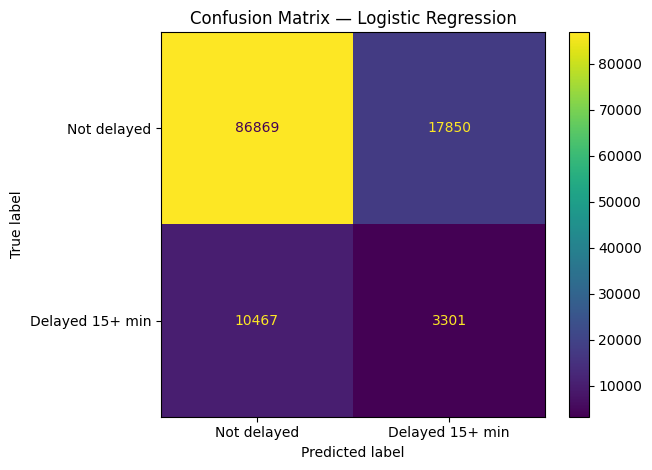

In [22]:

# ============================================================
# 12. CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_pred = prediction_store[best_model_name]["y_pred"]
best_prob = prediction_store[best_model_name]["y_prob"]

print("Selected model:", best_model_name)
print(classification_report(
    y_test,
    best_pred,
    labels=[0, 1],
    target_names=["Not delayed", "Delayed 15+ minutes"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    labels=[0, 1],
    display_labels=["Not delayed", "Delayed 15+ min"],
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


## 13. SHAP explainability

SHAP helps explain how features contribute to model predictions. This section explains the selected model using a manageable sample from the training set to keep computation practical.

For tree-based models, SHAP's tree explainer can be used directly on the transformed feature matrix. For Logistic Regression, a model-agnostic KernelExplainer can be expensive, so this notebook uses permutation importance as a fallback-style global interpretation and still reports that SHAP was not computed for that model. Do not describe permutation importance as SHAP.

Selected model: Logistic Regression
Encoded features: 679
Background sample: (30, 679)
Explanation sample: (50, 679)

Calculating SHAP values...
SHAP completed in 0.11 seconds.


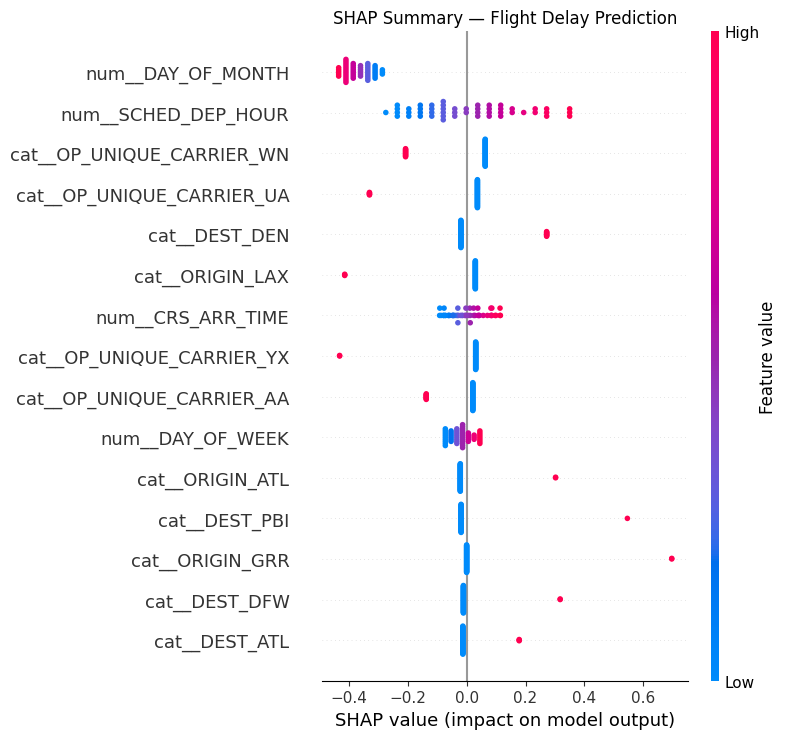

,Feature,Mean_Absolute_SHAP
0,num__DAY_OF_MONTH,0.367769
1,num__SCHED_DEP_HOUR,0.145248
2,cat__OP_UNIQUE_CARRIER_WN,0.097722
3,cat__OP_UNIQUE_CARRIER_UA,0.065998
4,cat__DEST_DEN,0.059782
5,cat__ORIGIN_LAX,0.052644
6,num__CRS_ARR_TIME,0.051890
7,cat__OP_UNIQUE_CARRIER_YX,0.046832
8,cat__OP_UNIQUE_CARRIER_AA,0.041989
9,num__DAY_OF_WEEK,0.036374


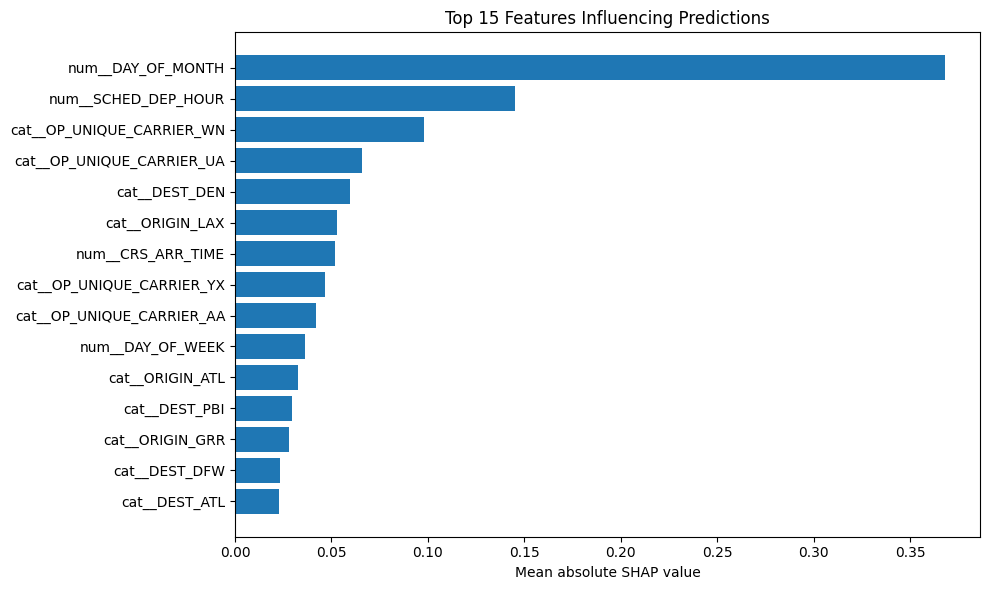

SHAP analysis finished.


In [28]:

# ============================================================
# 13. SHAP EXPLAINABILITY — SUPPORTS ALL FOUR MODELS
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import time

start_time = time.time()

# Retrieve the fitted preprocessing pipeline and classifier.
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
selected_estimator = best_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

print("Selected model:", best_model_name)
print("Encoded features:", len(feature_names))

# Sample before transforming to reduce computation and memory usage.
rng = np.random.default_rng(RANDOM_STATE)
n_background = min(30, len(X_train))
n_explain = min(50, len(X_test))

background_idx = rng.choice(
    len(X_train), n_background, replace=False
)
explain_idx = rng.choice(
    len(X_test), n_explain, replace=False
)

X_background = fitted_preprocessor.transform(
    X_train.iloc[background_idx]
)
X_explain = fitted_preprocessor.transform(
    X_test.iloc[explain_idx]
)

# Dense arrays are needed for some SHAP explainers.
if sparse.issparse(X_background):
    X_background = X_background.toarray()

if sparse.issparse(X_explain):
    X_explain = X_explain.toarray()

print("Background sample:", X_background.shape)
print("Explanation sample:", X_explain.shape)

# ------------------------------------------------------------
# Select a model-appropriate SHAP explainer.
# ------------------------------------------------------------
tree_model = best_model_name in [
    "Random Forest", "XGBoost", "LightGBM"
]

print("\nCalculating SHAP values...")

if tree_model:
    # TreeSHAP for tree-based classifiers.
    explainer = shap.TreeExplainer(
        selected_estimator,
        feature_perturbation="tree_path_dependent",
        model_output="raw"
    )

    shap_values = explainer.shap_values(
        X_explain,
        approximate=True,
        check_additivity=False
    )

    # Select positive-class explanations for binary classification.
    if isinstance(shap_values, list):
        shap_positive = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
        shap_positive = shap_values[:, :, 1]
    else:
        shap_positive = shap_values

    base_value = np.asarray(explainer.expected_value).reshape(-1)
    base_value = base_value[1] if len(base_value) > 1 else base_value[0]

else:
    # LinearExplainer is appropriate for Logistic Regression.
    explainer = shap.LinearExplainer(
        selected_estimator,
        X_background,
        feature_perturbation="interventional"
    )

    shap_values = explainer.shap_values(X_explain)
    shap_positive = (
        shap_values[1]
        if isinstance(shap_values, list)
        else shap_values
    )

    base_value = np.asarray(explainer.expected_value).reshape(-1)[0]

print(
    f"SHAP completed in {(time.time() - start_time):.2f} seconds."
)

# ------------------------------------------------------------
# Global explanation: summary plot
# ------------------------------------------------------------
shap.summary_plot(
    shap_positive,
    X_explain,
    feature_names=feature_names,
    max_display=15,
    show=False
)
plt.title("SHAP Summary — Flight Delay Prediction")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Rank features by mean absolute SHAP value.
# ------------------------------------------------------------
shap_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Mean_Absolute_SHAP": np.abs(shap_positive).mean(axis=0)
    })
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

display(shap_importance)

# Bar chart for reporting and dissertation use.
plot_data = shap_importance.sort_values("Mean_Absolute_SHAP")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["Mean_Absolute_SHAP"]
)
plt.xlabel("Mean absolute SHAP value")
plt.title("Top 15 Features Influencing Predictions")
plt.tight_layout()
plt.show()

print("SHAP analysis finished.")


## 14. Local explanation for one example flight (tree models only)

A local SHAP explanation shows which features push a single prediction higher or lower relative to the model's baseline. This helps connect the global explanation to an individual example. These are model explanations, not causal claims.

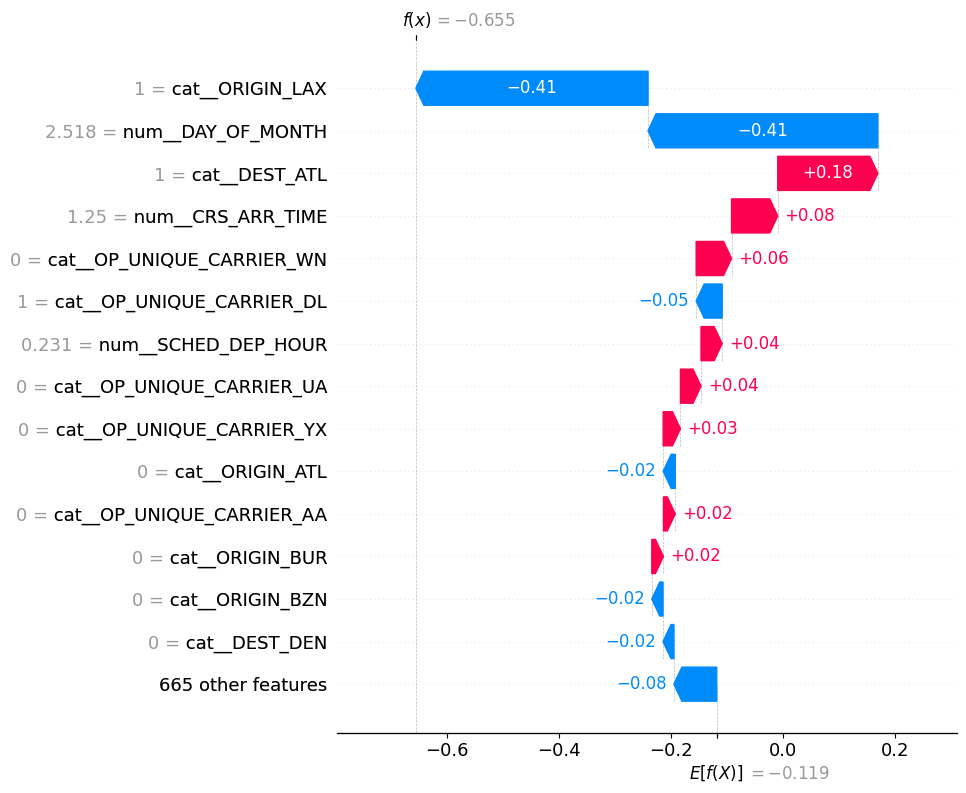

Local SHAP explanation generated successfully.
Selected model: Logistic Regression


In [29]:

# ============================================================
# 14. LOCAL SHAP EXPLANATION FOR ONE FLIGHT
# Supports Logistic Regression, Random Forest, XGBoost, LightGBM
# ============================================================

try:
    # Select the first flight from the SHAP explanation sample.
    one_row = X_explain[:1]

    # Reuse SHAP values calculated in Section 13.
    # This avoids running SHAP computation a second time.
    local_values = shap_positive[0]

    # Use the matching baseline created in Section 13.
    local_base_value = base_value

    # Create a local explanation for the selected flight.
    local_explanation = shap.Explanation(
        values=local_values,
        base_values=local_base_value,
        data=one_row[0],
        feature_names=feature_names
    )

    # Display the 15 strongest feature contributions.
    shap.plots.waterfall(
        local_explanation,
        max_display=15
    )

    print("Local SHAP explanation generated successfully.")
    print("Selected model:", best_model_name)

except Exception as exc:
    print("Could not generate the local SHAP plot.")
    print("Error:", repr(exc))


## 15. Save the results and model artifacts

This section saves the comparison table, selected fitted pipeline, and key run metadata. Download the files from Colab after the cell finishes. The fitted pipeline includes preprocessing and the classifier, so the same feature preparation can be applied during later inference.

In [30]:

# ============================================================
# 15. SAVE RESULTS AND MODEL ARTIFACTS
# ============================================================

import os
import json
import joblib

OUTPUT_DIR = "flight_delay_project_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison_results.csv"),
    index=False
)

joblib.dump(
    best_pipeline,
    os.path.join(OUTPUT_DIR, "best_flight_delay_pipeline.joblib")
)

metadata = {
    "dataset_file": DATA_PATH,
    "clean_rows": int(len(model_df)),
    "feature_columns": FEATURES,
    "target_column": TARGET,
    "split_method": split_method,
    "training_start": str(train_df["FL_DATE"].min()),
    "training_end": str(train_df["FL_DATE"].max()),
    "testing_start": str(test_df["FL_DATE"].min()),
    "testing_end": str(test_df["FL_DATE"].max()),
    "best_model_by_f1": best_model_name,
    "metrics": results_df.iloc[0].to_dict(),
    "note": "Dataset covers January 2025 only."
}

with open(
    os.path.join(OUTPUT_DIR, "run_metadata.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved results, model, and metadata to:", OUTPUT_DIR)


Saved results, model, and metadata to: flight_delay_project_outputs


## 16. Download the output files

Download the model comparison, fitted pipeline, and metadata. Keep the CSV results and notebook outputs because they will be useful when writing the dissertation and interpreting the experiment.

In [ ]:
from google.colab import files

files.download("flight_delay_project_outputs/model_comparison_results.csv")
files.download("flight_delay_project_outputs/best_flight_delay_pipeline.joblib")
files.download("flight_delay_project_outputs/run_metadata.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Final project summary template

Run this final cell to generate a compact summary from the actual model results. Copy the output into project notes, then interpret it alongside the EDA and SHAP plots. Do not claim that one algorithm is universally best; conclusions apply to this dataset, split, feature set, and configuration.

In [32]:

# ============================================================
# 16. FINAL EXPERIMENT SUMMARY
# ============================================================

best_row = results_df.iloc[0]

print("=" * 65)
print("FLIGHT DELAY PREDICTION — FINAL EXPERIMENT SUMMARY")
print("=" * 65)
print("Clean records:", f"{len(model_df):,}")
print("Features:", ", ".join(FEATURES))
print("Target:", TARGET)
print("Split:", split_method)
print("Training period:",
      train_df["FL_DATE"].min().date(), "to",
      train_df["FL_DATE"].max().date())
print("Testing period:",
      test_df["FL_DATE"].min().date(), "to",
      test_df["FL_DATE"].max().date())
print("Best model by F1-score:", best_row["Model"])
print(f"Accuracy:  {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall:    {best_row['Recall']:.4f}")
print(f"F1-score:  {best_row['F1-score']:.4f}")
print(f"ROC-AUC:   {best_row['ROC-AUC']:.4f}")



FLIGHT DELAY PREDICTION — FINAL EXPERIMENT SUMMARY
Clean records: 522,269
Features: YEAR, MONTH, DAY_OF_MONTH, DAY_OF_WEEK, CRS_ARR_TIME, OP_UNIQUE_CARRIER, ORIGIN, DEST, DISTANCE, SCHED_DEP_HOUR
Target: ARR_DEL15
Split: Chronological split by unique flight date (80/20)
Training period: 2025-01-01 to 2025-01-24
Testing period: 2025-01-25 to 2025-01-31
Best model by F1-score: Logistic Regression
Accuracy:  0.7610
Precision: 0.1561
Recall:    0.2398
F1-score:  0.1891
ROC-AUC:   0.5646
